### EXPERIMENT 1: EDGES AND DERIVATIVES

Objective: Understand step edges, ramp edges, and their derivatives.

Tasks:
 1. Construct synthetic step and ramp edges.
 2. Compute first- and second-order derivatives.
 3. Compare the resulting intensity profiles.

Question: Why is the second derivative more sensitive to noise?


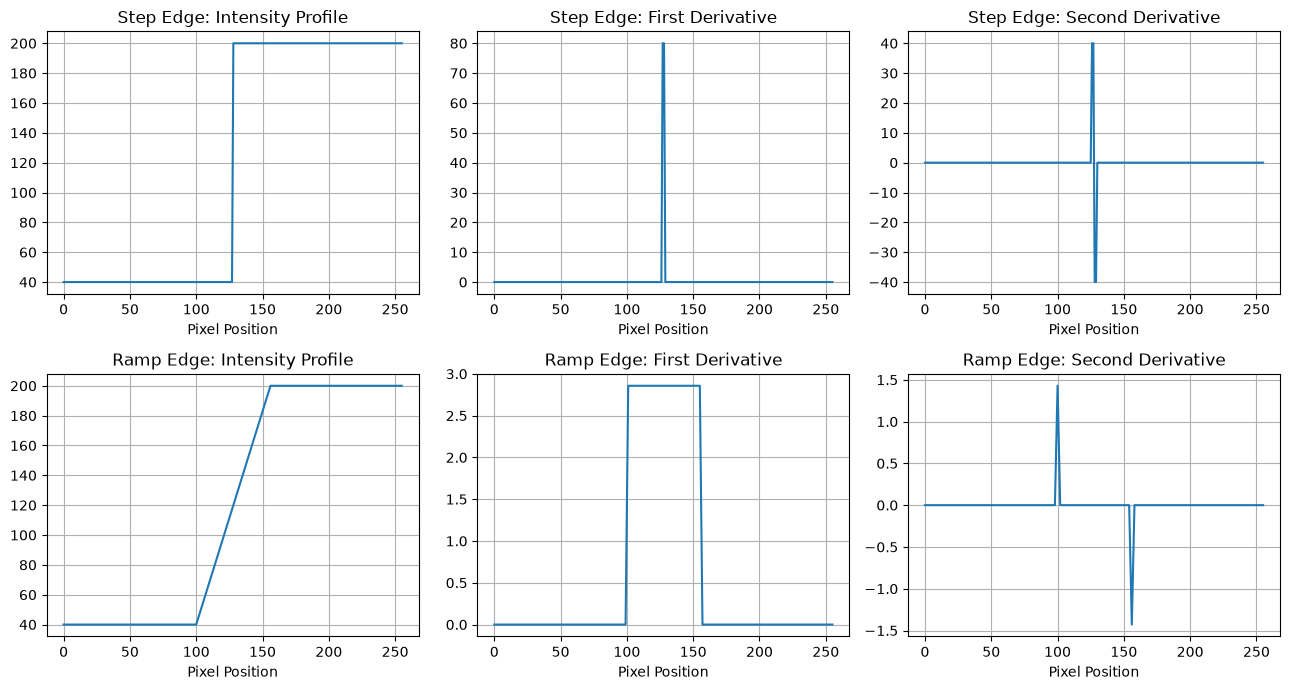

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(256)

step = np.where(x >= 128, 200.0, 40.0)
ramp = np.interp(x, [0, 100, 156, 255], [40, 40, 200, 200])

fig, axes = plt.subplots(2, 3, figsize=(13, 7))

for i, (signal, name) in enumerate([
    (step, "Step Edge"),
    (ramp, "Ramp Edge")
]):
    first = np.gradient(signal)
    second = np.gradient(first)

    for j, (values, title) in enumerate([
        (signal, "Intensity Profile"),
        (first, "First Derivative"),
        (second, "Second Derivative")
    ]):
        axes[i, j].plot(x, values)
        axes[i, j].set_title(f"{name}: {title}")
        axes[i, j].set_xlabel("Pixel Position")
        axes[i, j].grid(True)

plt.tight_layout()
plt.show()

### EXPERIMENT 2: ROBERTS EDGE DETECTOR

Objective: Implement Roberts cross-gradient operators.

Tasks:
 1. Define the two Roberts kernels.
 2. Compute directional gradient responses.
 3. Combine the responses using gradient magnitude.

Question: How does the 2×2 neighborhood affect noise sensitivity?


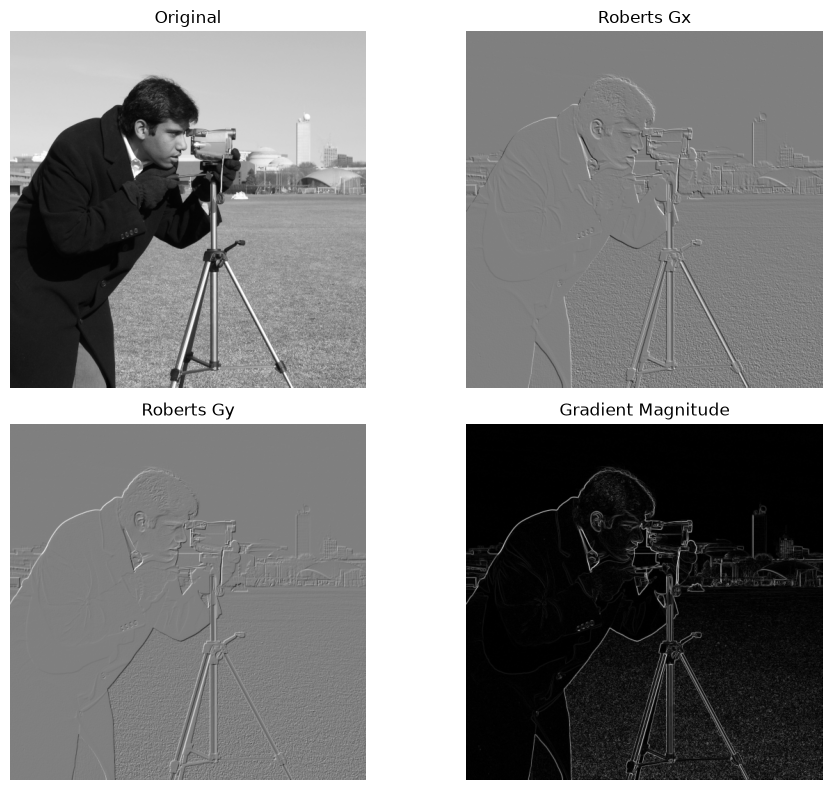

In [ ]:
from skimage import data
from scipy.ndimage import convolve
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

kx = np.array([
    [0, -1],
    [1,  0]
])

ky = np.array([
    [-1, 0],
    [ 0, 1]
])

gx = convolve(img, kx, mode="reflect")
gy = convolve(img, ky, mode="reflect")
magnitude = np.hypot(gx, gy)

images = [img, gx, gy, magnitude]
titles = ["Original", "Roberts Gx", "Roberts Gy", "Gradient Magnitude"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, image, title in zip(axes.flat, images, titles):
    if title in ["Roberts Gx", "Roberts Gy"]:
        limit = max(np.max(np.abs(image)), 1)
        ax.imshow(image, cmap="gray", vmin=-limit, vmax=limit)
    elif title == "Gradient Magnitude":
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 3: PREWITT EDGE DETECTOR

Objective: Compute horizontal and vertical Prewitt gradients.

Tasks:
 1. Apply the Prewitt kernels.
 2. Visualize signed directional responses.
 3. Compute the combined gradient magnitude.

Question: Why do Prewitt kernels have coefficients that sum to zero?



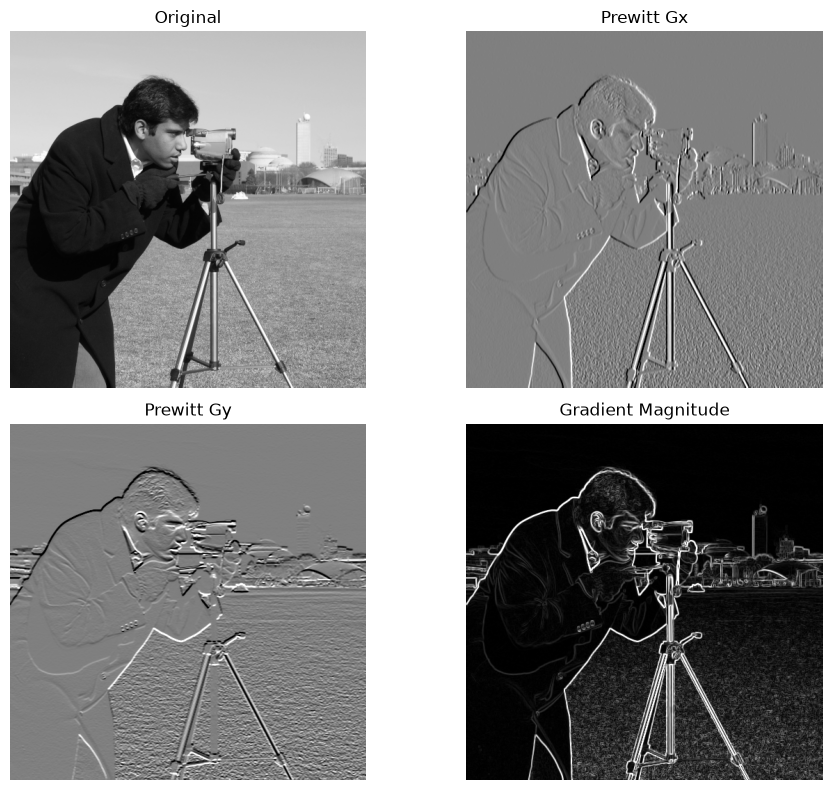

In [3]:
from skimage import data
from scipy.ndimage import correlate
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

kx = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
])

ky = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
])

gx = correlate(img, kx, mode="reflect")
gy = correlate(img, ky, mode="reflect")
magnitude = np.hypot(gx, gy)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

images = [img, gx, gy, magnitude]
titles = ["Original", "Prewitt Gx", "Prewitt Gy", "Gradient Magnitude"]

for ax, image, title in zip(axes.flat, images, titles):
    if title in ["Prewitt Gx", "Prewitt Gy"]:
        limit = max(np.percentile(np.abs(image), 99), 1)
        ax.imshow(image, cmap="gray", vmin=-limit, vmax=limit)
    elif title == "Gradient Magnitude":
        ax.imshow(image, cmap="gray", vmin=0,
                  vmax=max(np.percentile(image, 99), 1))
    else:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 4: SOBEL EDGE DETECTOR

Objective: Investigate the Sobel gradient operator.

Tasks:
 1. Apply horizontal and vertical Sobel kernels.
 2. Compute gradient magnitude.
 3. Compare the results with Prewitt.

Question: Why does Sobel assign a weight of 2 to central coefficients?

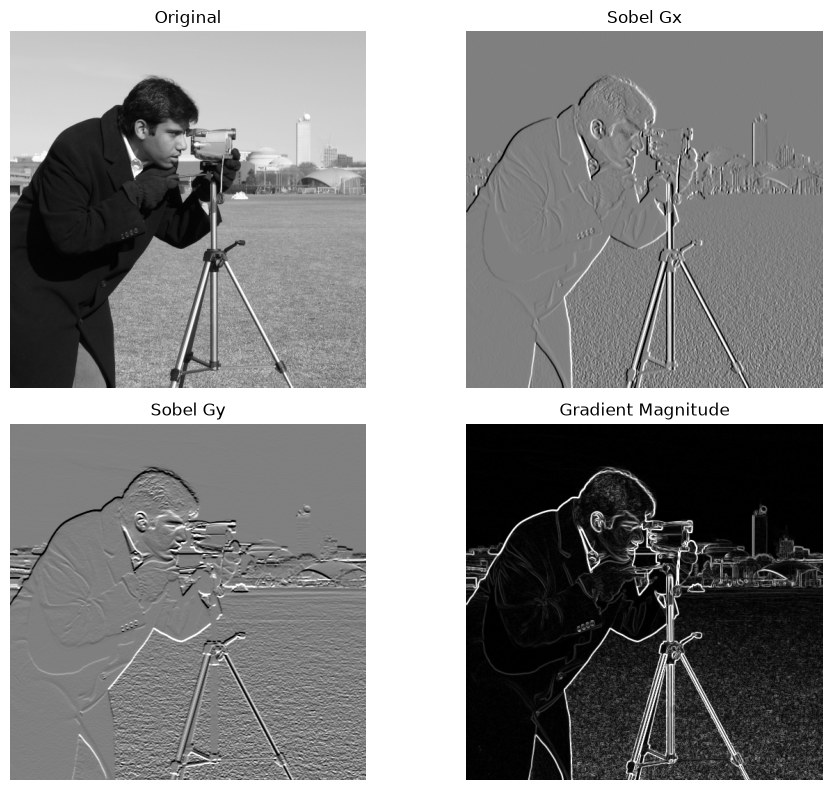

In [4]:
from skimage import data
from scipy.ndimage import correlate
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

kx = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

ky = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
])

gx = correlate(img, kx, mode="reflect")
gy = correlate(img, ky, mode="reflect")
magnitude = np.hypot(gx, gy)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

images = [img, gx, gy, magnitude]
titles = ["Original", "Sobel Gx", "Sobel Gy", "Gradient Magnitude"]

for ax, image, title in zip(axes.flat, images, titles):
    if title in ["Sobel Gx", "Sobel Gy"]:
        limit = max(np.percentile(np.abs(image), 99), 1)
        ax.imshow(image, cmap="gray", vmin=-limit, vmax=limit)
    elif title == "Gradient Magnitude":
        ax.imshow(image, cmap="gray", vmin=0,
                  vmax=max(np.percentile(image, 99), 1))
    else:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 5: GRADIENT THRESHOLDING

Objective: Investigate the influence of threshold selection.

Tasks:
 1. Compute the Sobel gradient magnitude.
 2. Normalize the response to [0, 1].
 3. Apply different thresholds.

Question: How do low and high thresholds affect false edges and missed edges?

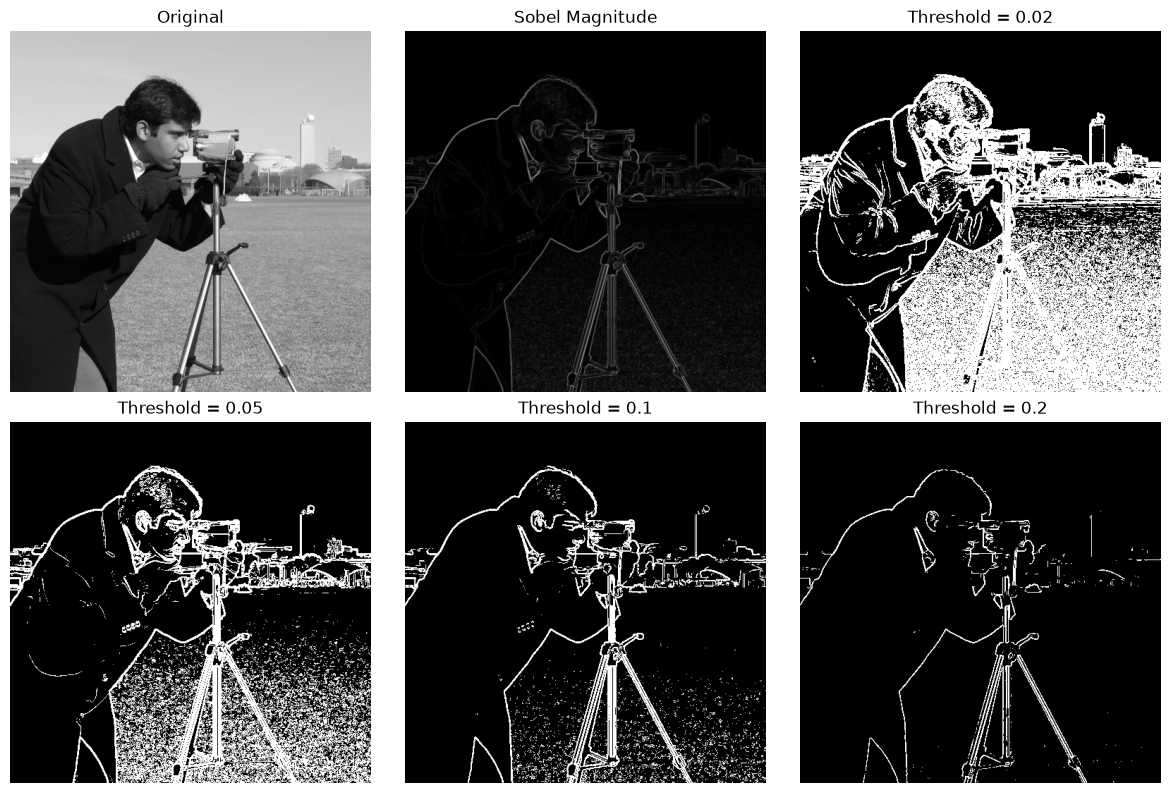

In [5]:
from skimage import data, filters
import numpy as np
import matplotlib.pyplot as plt

img = data.camera()

gradient = filters.sobel(img)
thresholds = [0.02, 0.05, 0.10, 0.20]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

axes.flat[0].imshow(img, cmap="gray")
axes.flat[0].set_title("Original")
axes.flat[0].axis("off")

axes.flat[1].imshow(gradient, cmap="gray", vmin=0, vmax=1)
axes.flat[1].set_title("Sobel Magnitude")
axes.flat[1].axis("off")

for ax, threshold in zip(axes.flat[2:], thresholds):
    edges = gradient > threshold

    ax.imshow(edges, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Threshold = {threshold}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 6: COMPASS EDGE DETECTORS

Objective: Investigate directional edge detection using compass masks.

Tasks:
 1. Construct eight Kirsch directional kernels.
 2. Apply each kernel to a grayscale image.
 3. Combine responses using maximum absolute magnitude.

Question: What advantage do compass operators offer over two-directional gradients?

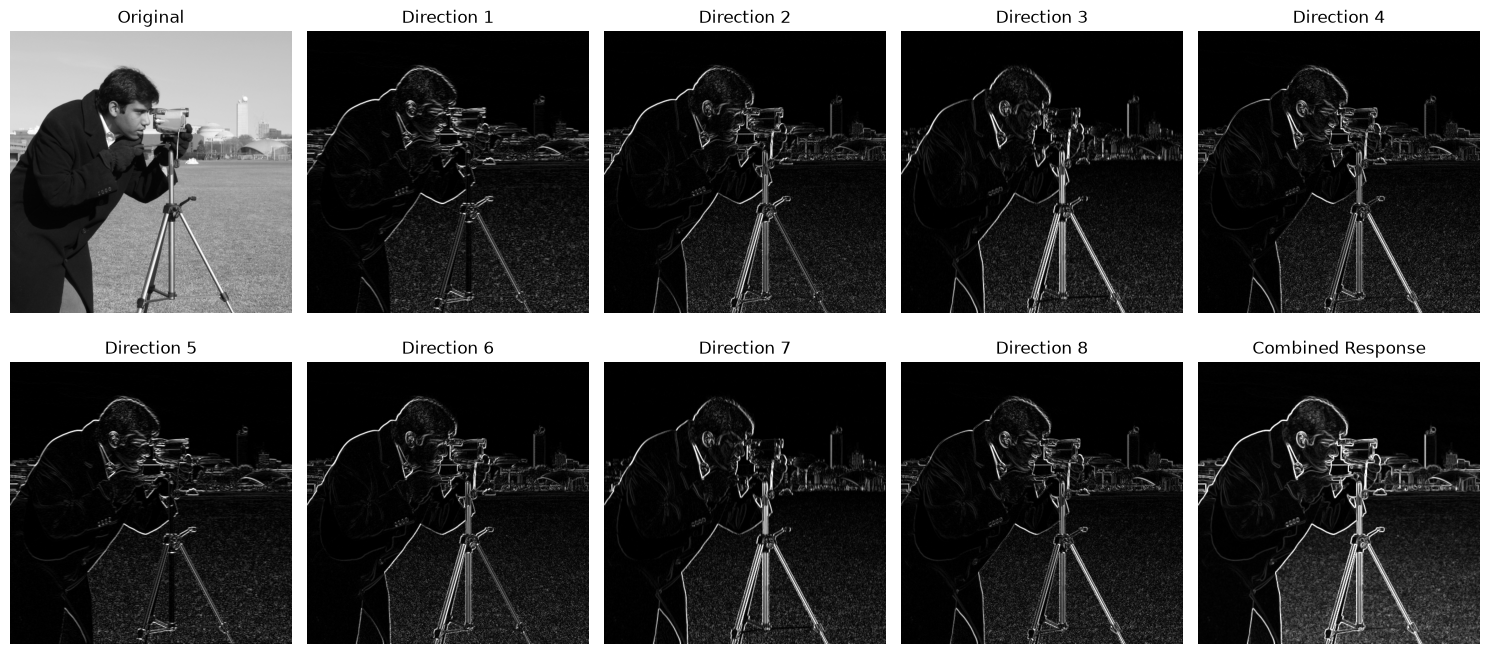

In [7]:
from skimage import data
from scipy.ndimage import correlate
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

# Kirsch north-direction kernel
north = np.array([
    [ 5,  5,  5],
    [-3,  0, -3],
    [-3, -3, -3]
])

# Generate all eight compass directions
directions = [
    north,
    np.array([[5, 5, -3], [5, 0, -3], [-3, -3, -3]]),
    np.rot90(north, -1),
    np.array([[-3, 5, 5], [-3, 0, 5], [-3, -3, -3]]),
    np.rot90(north, 2),
    np.array([[-3, -3, -3], [-3, 0, 5], [-3, 5, 5]]),
    np.rot90(north, 1),
    np.array([[-3, -3, -3], [5, 0, -3], [5, 5, -3]])
]

# Maximum absolute directional response
responses = np.stack([
    correlate(img, kernel, mode="reflect")
    for kernel in directions
])

combined = np.max(np.abs(responses), axis=0)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

axes.flat[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes.flat[0].set_title("Original")

for i in range(8):
    axes.flat[i + 1].imshow(
        np.abs(responses[i]), cmap="gray",
        vmin=0, vmax=np.percentile(combined, 99)
    )
    axes.flat[i + 1].set_title(f"Direction {i + 1}")

axes.flat[9].imshow(
    combined, cmap="gray",
    vmin=0, vmax=np.percentile(combined, 99)
)
axes.flat[9].set_title("Combined Response")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 7: LAPLACIAN EDGE DETECTOR

Objective: Investigate second-order derivatives and noise sensitivity.

Tasks:
 1. Apply the 8-neighbor Laplacian kernel.
 2. Introduce Gaussian noise and repeat the operation.
 3. Compare the Laplacian responses.

Question: Why does the Laplacian amplify noise?

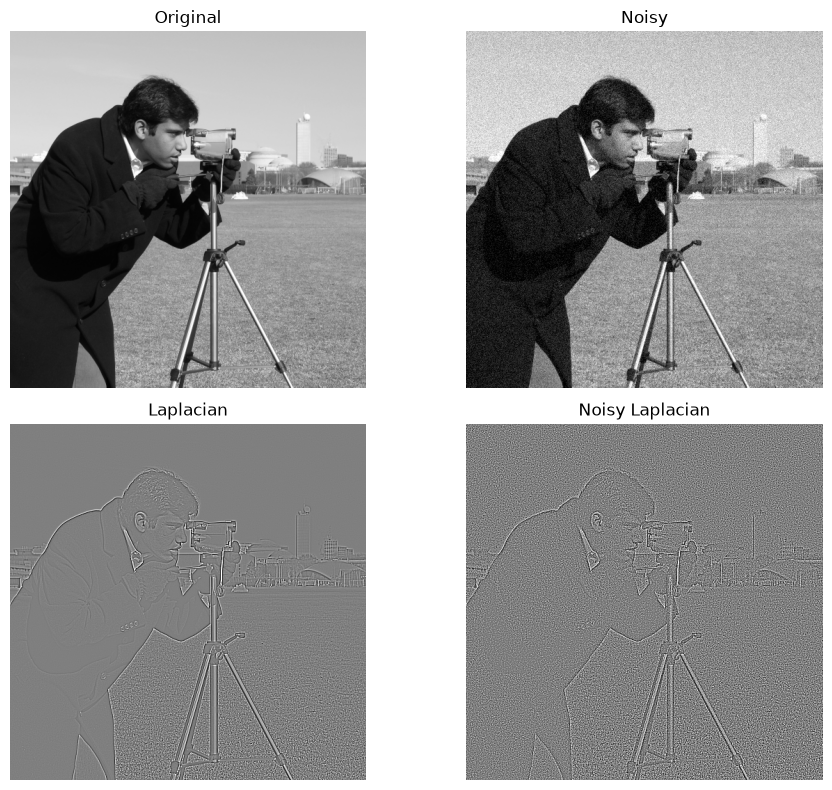

In [8]:
from skimage import data
from scipy.ndimage import correlate
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float)

rng = np.random.default_rng(42)
noisy = np.clip(img + rng.normal(0, 15, img.shape), 0, 255)

kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

lap_original = correlate(img, kernel, mode="reflect")
lap_noisy = correlate(noisy, kernel, mode="reflect")

limit = max(np.percentile(np.abs(lap_noisy), 99), 1)

images = [img, noisy, lap_original, lap_noisy]
titles = ["Original", "Noisy", "Laplacian", "Noisy Laplacian"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, image, title in zip(axes.flat, images, titles):
    if "Laplacian" in title:
        ax.imshow(image, cmap="gray", vmin=-limit, vmax=limit)
    else:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 8: LAPLACIAN OF GAUSSIAN (LoG)

Objective: Investigate Gaussian smoothing before second-order edge detection.

Tasks:
 1. Apply LoG using different sigma values.
 2. Detect zero crossings of the filtered response.
 3. Compare the resulting edge maps.

Question: How does increasing sigma affect noise and edge localization?


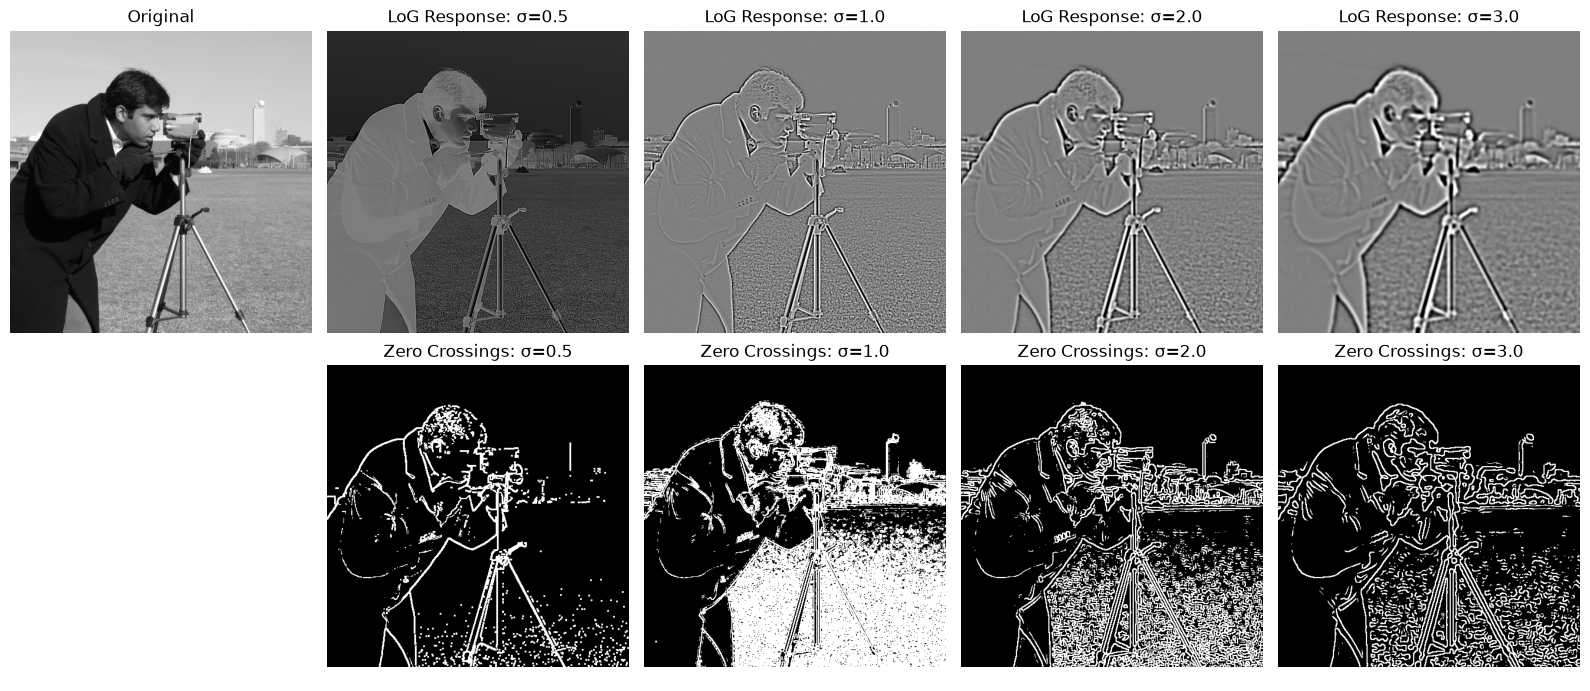

In [9]:
from skimage import data
from scipy.ndimage import gaussian_laplace, maximum_filter, minimum_filter
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float) / 255

sigmas = [0.5, 1.0, 2.0, 3.0]

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

axes[1, 0].axis("off")

for i, sigma in enumerate(sigmas):
    log_response = gaussian_laplace(img, sigma=sigma)

    # Detect local sign changes with sufficient response variation
    local_max = maximum_filter(log_response, size=3)
    local_min = minimum_filter(log_response, size=3)

    zero_crossings = (local_min < 0) & (local_max > 0)
    strength = local_max - local_min

    edges = zero_crossings & (strength > 0.05 * strength.max())

    limit = max(np.percentile(np.abs(log_response), 99), 1e-12)

    axes[0, i + 1].imshow(
        log_response, cmap="gray", vmin=-limit, vmax=limit
    )
    axes[0, i + 1].set_title(f"LoG Response: σ={sigma}")

    axes[1, i + 1].imshow(edges, cmap="gray", vmin=0, vmax=1)
    axes[1, i + 1].set_title(f"Zero Crossings: σ={sigma}")

    axes[0, i + 1].axis("off")
    axes[1, i + 1].axis("off")

plt.tight_layout()
plt.show()

### EXPERIMENT 9: CANNY EDGE DETECTOR

Objective: Investigate the effects of Gaussian smoothing and hysteresis thresholds.

Tasks:
 1. Apply Canny with different sigma values.
 2. Investigate low and high threshold selection.
 3. Compare edge continuity and noise sensitivity.

Question: Why does Canny use two thresholds instead of one?


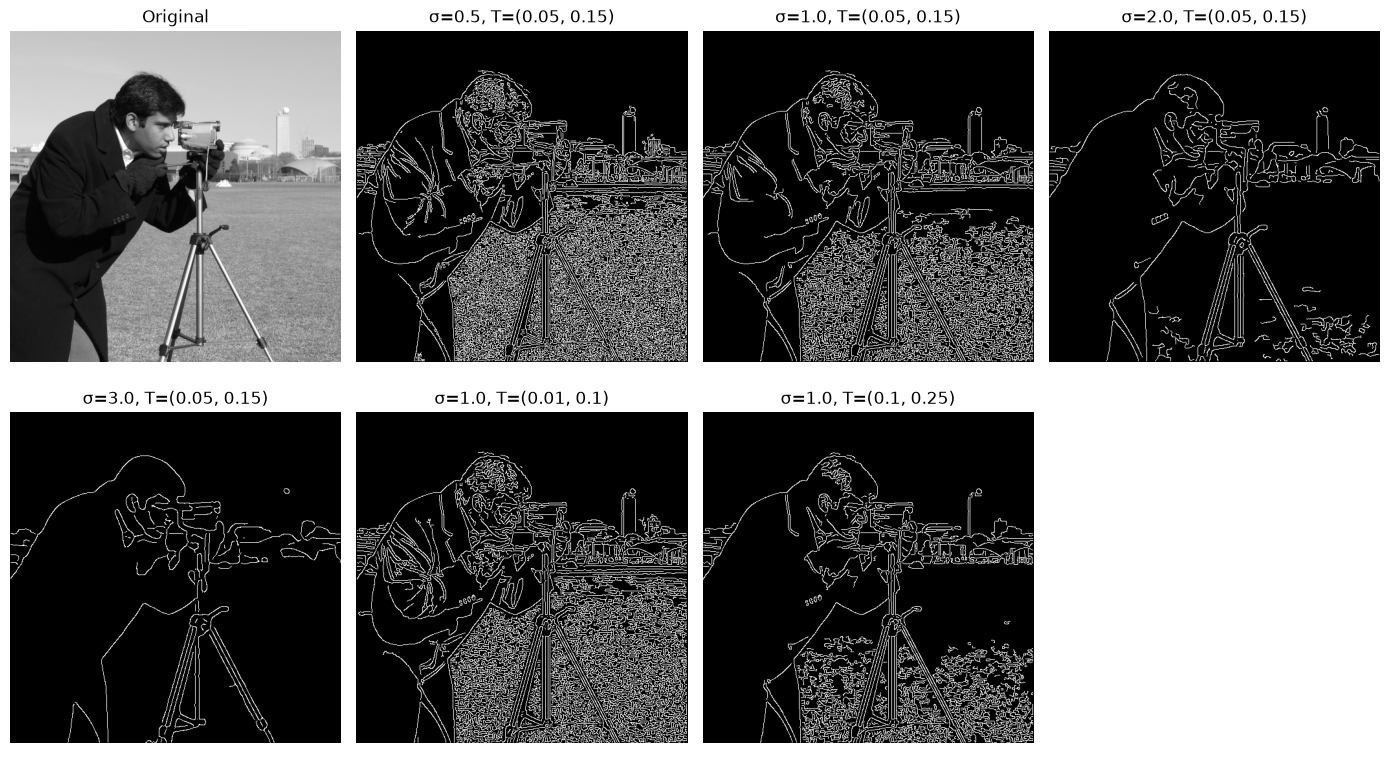

In [10]:
from skimage import data, feature
import numpy as np
import matplotlib.pyplot as plt

img = data.camera().astype(float) / 255

parameters = [
    (0.5, 0.05, 0.15),
    (1.0, 0.05, 0.15),
    (2.0, 0.05, 0.15),
    (3.0, 0.05, 0.15),
    (1.0, 0.01, 0.10),
    (1.0, 0.10, 0.25)
]

fig, axes = plt.subplots(2, 4, figsize=(14, 8))

axes.flat[0].imshow(img, cmap="gray", vmin=0, vmax=1)
axes.flat[0].set_title("Original")
axes.flat[0].axis("off")

for ax, (sigma, low, high) in zip(axes.flat[1:], parameters):
    edges = feature.canny(
        img,
        sigma=sigma,
        low_threshold=low,
        high_threshold=high,
        use_quantiles=False
    )

    ax.imshow(edges, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"σ={sigma}, T=({low}, {high})")
    ax.axis("off")

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()